# KD Example

Minimal examples using the metric modules with the two reconstructions in `recons/`.

In [1]:
from pathlib import Path

import cfr
import xarray as xr

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

from metrics import KD_test as kd

## Load reconstructions

In [2]:
res_lmr = cfr.ReconRes(str(ROOT / "recons" / "lmr21"))
res_lmr.load(["tas", "tas_gm"])
lmr_fd = res_lmr.da["tas"]
lmr_ts = res_lmr.recons["tas_gm"]

res_presto = cfr.ReconRes(str(ROOT / "recons" / "presto2k"))
res_presto.load(["tas", "tas_gm"])
presto_fd = res_presto.da["tas"]
presto_ts = res_presto.recons["tas_gm"]

print(lmr_fd.shape)
print(presto_fd.shape)

(2000, 5, 42, 63)
(2000, 5, 42, 63)


## Compute and plot

Computing KD statistic for LMRv2.1 vs PReSto2k...
Processing year 0/2000 (year 1)...
Processing year 100/2000 (year 101)...
Processing year 200/2000 (year 201)...
Processing year 300/2000 (year 301)...
Processing year 400/2000 (year 401)...
Processing year 500/2000 (year 501)...
Processing year 600/2000 (year 601)...
Processing year 700/2000 (year 701)...
Processing year 800/2000 (year 801)...
Processing year 900/2000 (year 901)...
Processing year 1000/2000 (year 1001)...
Processing year 1100/2000 (year 1101)...
Processing year 1200/2000 (year 1201)...
Processing year 1300/2000 (year 1301)...
Processing year 1400/2000 (year 1401)...
Processing year 1500/2000 (year 1501)...
Processing year 1600/2000 (year 1601)...
Processing year 1700/2000 (year 1701)...
Processing year 1800/2000 (year 1801)...
Processing year 1900/2000 (year 1901)...

Completed 2000 years
KD range: [0.2000, 0.8000]
Raw p-value range: [8.1519e-02, 9.9997e-01]

=== Statistical Summary (Benjamini-Yekutieli FDR) ===
Signif

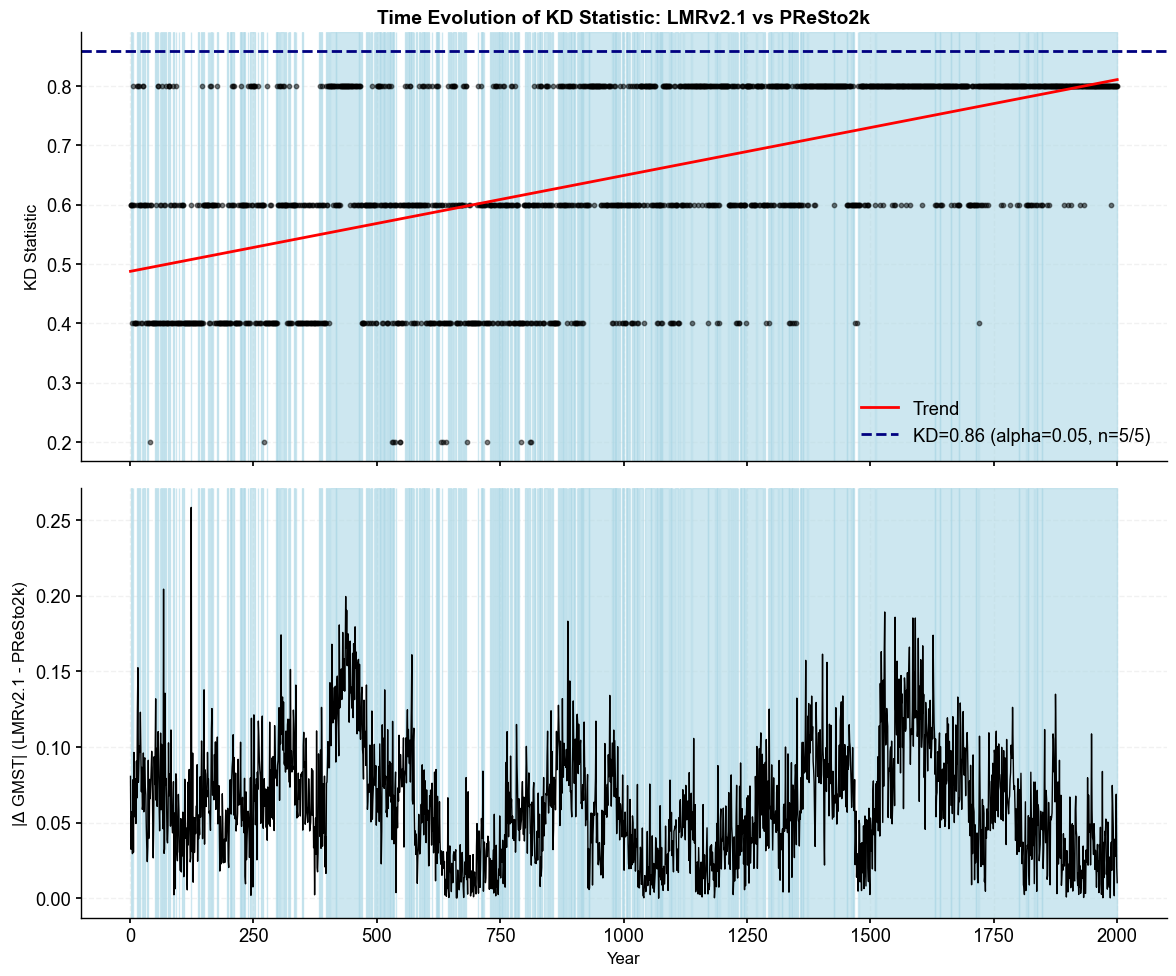

In [10]:
results = kd.compute_and_plot_kd(
    lmr_fd,
    presto_fd,
    lmr_ts,
    presto_ts,
    "LMRv2.1",
    "PReSto2k",
    highlight_threshold=0.6,
)

## EOF example

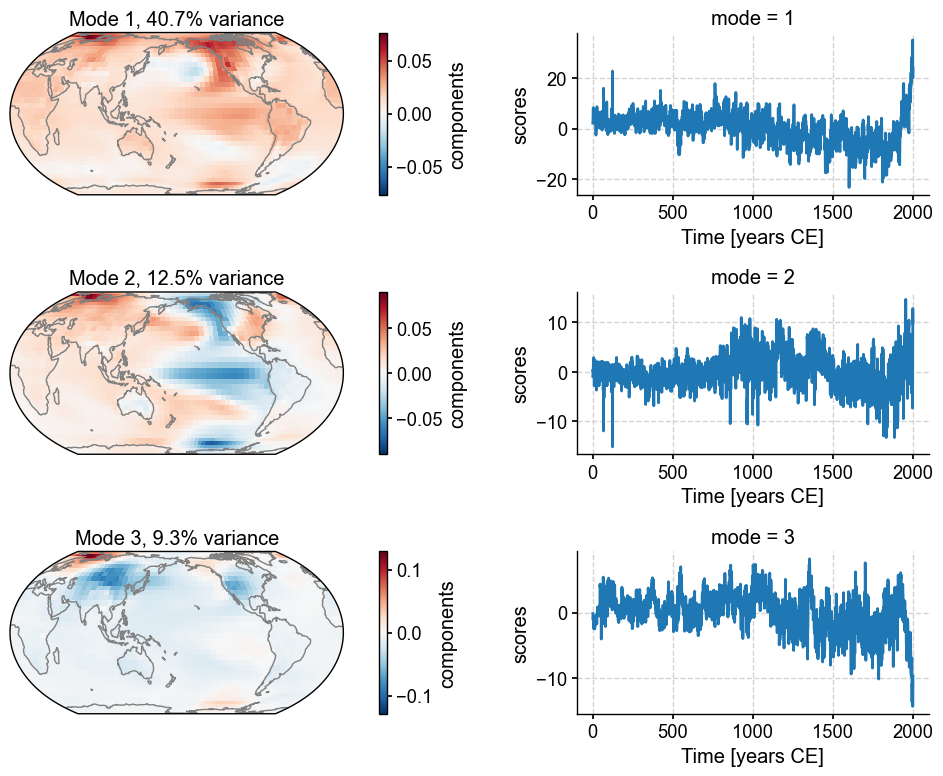

In [4]:
from metrics import EOF as eof

lmr_tas = lmr_fd.mean(dim="ens")

eof_lmr, expvar_lmr, components_lmr, scores_lmr, fig = eof.plot_eofs(lmr_tas)

## EOF difference example

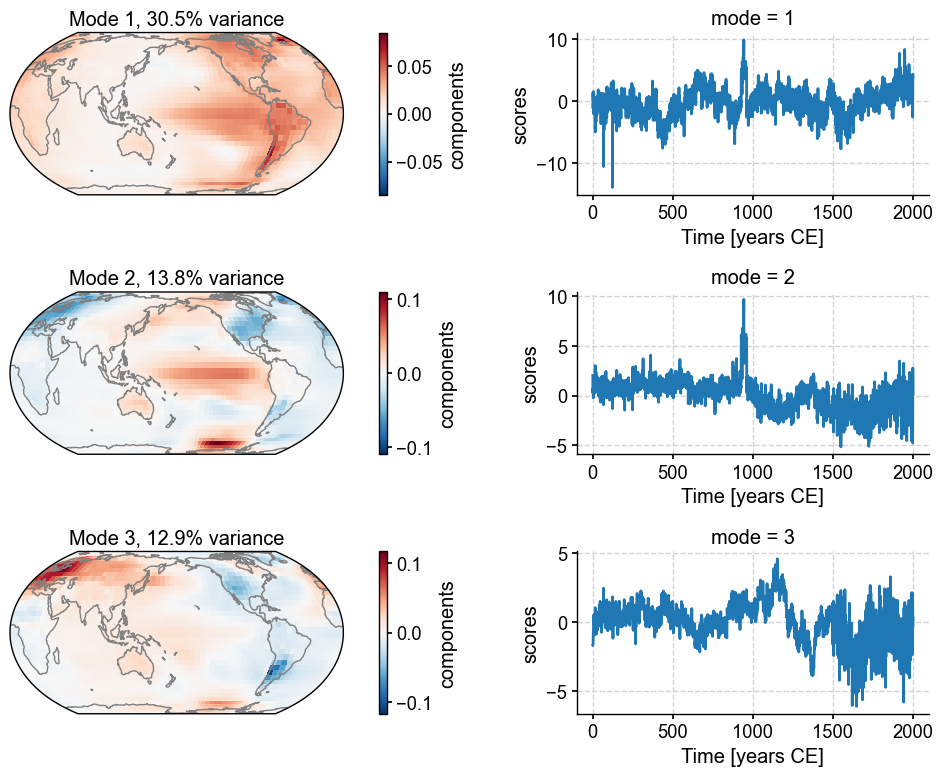

In [5]:
diff_tas = presto_fd.mean(dim="ens") - lmr_fd.mean(dim="ens")

eof_diff, expvar_diff, components_diff, scores_diff, fig = eof.plot_eofs(diff_tas)

## Volcano example

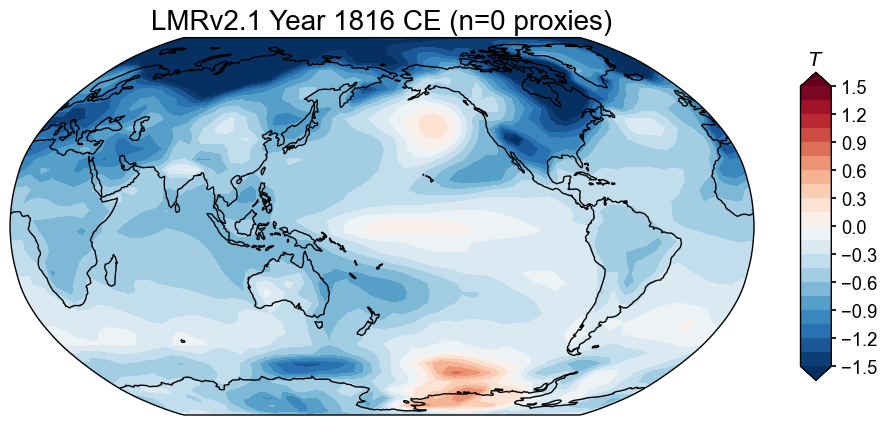

In [6]:
from metrics import volcano

volcanic_year = 1816

filtered_pdb_1816, fig, ax = volcano.plot_volcanic_year(
    res_lmr.recons["tas"],
    year=volcanic_year,
    name="LMRv2.1",
    plot_proxydb=False,
)

## SEA top 10

In [7]:
from metrics import SEA as sea

aod = xr.open_dataset(ROOT / "data" / "eVolv2k_v3_EVA_AOD_-500_1900_1.nc")
gm_aod = aod["aod550"].mean(dim="lat")

top10_events = sea.top_events_from_aod(gm_aod, min_sep_years=5, max_events=10)
top10_events

,year,aod550
0,1258,0.500182
1,1458,0.347899
2,540,0.325112
3,1815,0.324038
4,682,0.300077
5,574,0.270851
6,1230,0.251977
7,1783,0.248842
8,266,0.222099
9,1809,0.217057


### Plot composites

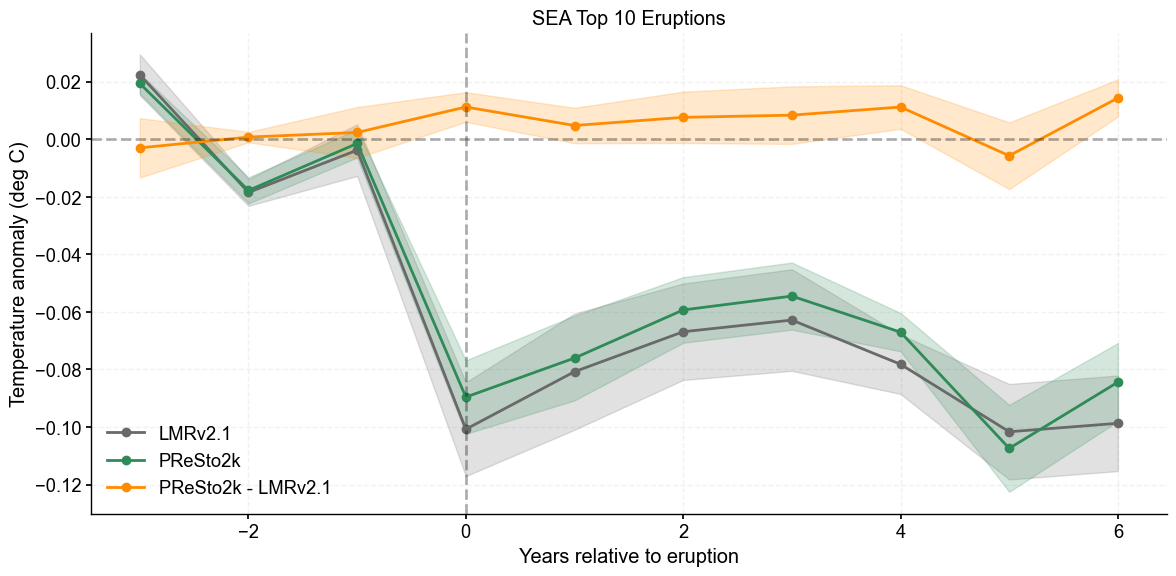

In [8]:
top10_years = top10_events["year"].values

lmr_sea_top10 = sea.sea_composite_ensemble(lmr_ts, top10_years)
presto_sea_top10 = sea.sea_composite_ensemble(presto_ts, top10_years)
diff_sea_top10 = sea.difference_ensemble_sea(
    lmr_sea_top10,
    presto_sea_top10,
    name="PReSto2k - LMRv2.1",
)

fig, ax = sea.plot_ensemble_sea(
    [lmr_sea_top10, presto_sea_top10, diff_sea_top10],
    ["LMRv2.1", "PReSto2k", "PReSto2k - LMRv2.1"],
    ["dimgray", "seagreen", "darkorange"],
    title="SEA Top 10 Eruptions",
)

### Post-eruption year 1 field significance

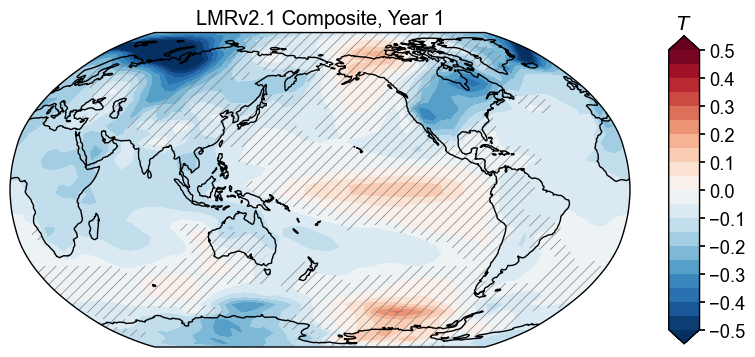

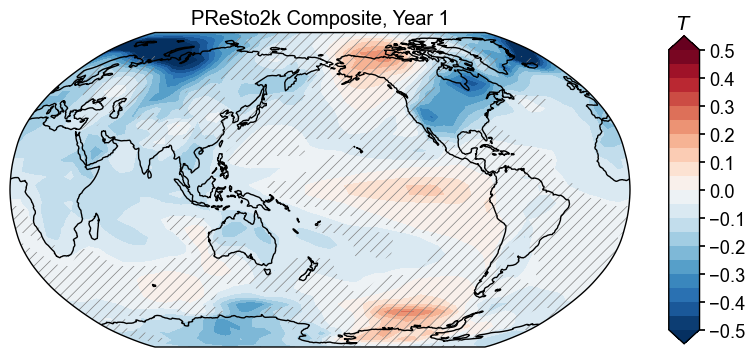

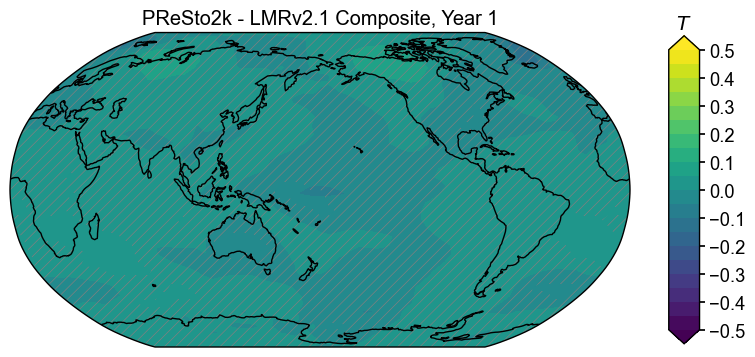

In [9]:
lmr_field = res_lmr.recons["tas"]
presto_field = res_presto.recons["tas"]
diff_field = sea.difference_field(lmr_field, presto_field, name="PReSto2k - LMRv2.1")

sea_field_lag1 = {}
for name, field in [
    ("LMRv2.1", lmr_field),
    ("PReSto2k", presto_field),
    ("PReSto2k - LMRv2.1", diff_field),
]:
    sea_field_lag1[name] = sea.plot_field_sea_sig(
        top10_events,
        field,
        lag=1,
        name=name,
        n_perm=200,
    )